# 02 — Leave-one-contract-out evaluation against baselines

Each demo contract is held out in turn. The GAT is retrained on the other five (100 epochs, Adam, lr 0.005, weight decay 1e-4) for five seeds. The sink-presence rule and a logistic regression on pooled node features are evaluated under the same folds.

The evaluation writes `results/metrics.json`, the per-decision CSVs and the figures. This cell takes a few minutes on CPU.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import platform, torch, networkx, sklearn, matplotlib
print("python", platform.python_version(), "| torch", torch.__version__,
      "| networkx", networkx.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

python 3.13.3 | torch 2.13.0+cpu | networkx 3.6.1 | scikit-learn 1.9.0 | matplotlib 3.11.1


In [2]:
import evaluate
evaluate.main()

[*] Processing contracts to build GNN dataset...
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling ./demo_contracts\ReentrancyVulnerable.sol...
[+] Loaded ReentrancyVulnerable.sol (Nodes: 30, Edges: 54)
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling ./demo_contracts\ReentrancySafe.sol...


[+] Loaded ReentrancySafe.sol (Nodes: 32, Edges: 58)
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling ./demo_contracts\TimestampVulnerable.sol...
[+] Loaded TimestampVulnerable.sol (Nodes: 13, Edges: 22)
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling ./demo_contracts\TimestampSafe.sol...
[+] Loaded TimestampSafe.sol (Nodes: 19, Edges: 32)
[*] Detected pragma version requirement. Using solc 0.7.6
[*] Compiling ./demo_contracts\ArithmeticVulnerable.sol...


[+] Loaded ArithmeticVulnerable.sol (Nodes: 18, Edges: 18)
[*] Detected pragma version requirement. Using solc 0.8.20
[*] Compiling ./demo_contracts\ArithmeticSafe.sol...
[+] Loaded ArithmeticSafe.sol (Nodes: 43, Edges: 77)
[*] LOCO GAT, seed 0


[*] LOCO GAT, seed 1


[*] LOCO GAT, seed 2


[*] LOCO GAT, seed 3


[*] LOCO GAT, seed 4



LOCO summary (18 class decisions per method)
  GAT (LOCO, mean of 5 seeds)              P=0.000 R=0.000 F1=0.000 Acc=0.778
  Sink-presence rule (no learning)         P=0.333 R=1.000 F1=0.500 Acc=0.667
  Logistic regression, pooled features     P=0.000 R=0.000 F1=0.000 Acc=0.833
  GAT std across seeds: precision=0.000, recall=0.000, f1=0.000, accuracy=0.000
  GAT in-sample (saved weights): P=1.000 R=1.000 F1=1.000 Acc=1.000
  GAT localization (LOCO, vulnerable contracts): mean precision=0.000, mean recall=0.000, n=15


## 1. Summary table

Each method gives 18 binary decisions (6 contracts x 3 classes). Only 3 of the 18 are positive, so precision and recall are very sensitive to single decisions.

In [3]:
import json, pandas as pd
m = json.load(open("results/metrics.json"))
rows = {
    "GAT, leave-one-out (mean of 5 seeds)": m["gat_loco_mean"],
    "Sink-presence rule (no learning)": {k: m["sink_rule"][k] for k in ["precision","recall","f1","accuracy"]},
    "Logistic regression, pooled features": {k: m["logistic_loco"][k] for k in ["precision","recall","f1","accuracy"]},
    "GAT, trained and tested on same 6 (saved weights)": {k: m["gat_in_sample_saved_weights"][k] for k in ["precision","recall","f1","accuracy"]},
}
df = pd.DataFrame(rows).T.round(3)
display(df)
print("GAT std across seeds:", {k: round(v, 3) for k, v in m["gat_loco_std"].items()})
print("GAT localization, leave-one-out, vulnerable contracts:", m["gat_localization_loco"])

,precision,recall,f1,accuracy
"GAT, leave-one-out (mean of 5 seeds)",0.000,0.0,0.0,0.778
Sink-presence rule (no learning),0.333,1.0,0.5,0.667
"Logistic regression, pooled features",0.000,0.0,0.0,0.833
"GAT, trained and tested on same 6 (saved weights)",1.000,1.0,1.0,1.000


GAT std across seeds: {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.0}
GAT localization, leave-one-out, vulnerable contracts: {'mean_precision': 0.0, 'mean_recall': 0.0, 'rows': 15}


## 2. Confusion counts

In [4]:
counts = pd.DataFrame({k: m[k] for k in ["sink_rule", "logistic_loco", "gat_in_sample_saved_weights"]}).T[["TP","FP","TN","FN"]]
counts.index = ["sink rule (LOCO)", "logistic (LOCO)", "GAT in-sample"]
display(counts)

,TP,FP,TN,FN
sink rule (LOCO),3.0,6.0,9.0,0.0
logistic (LOCO),0.0,0.0,15.0,3.0
GAT in-sample,3.0,0.0,15.0,0.0


## 3. Figures

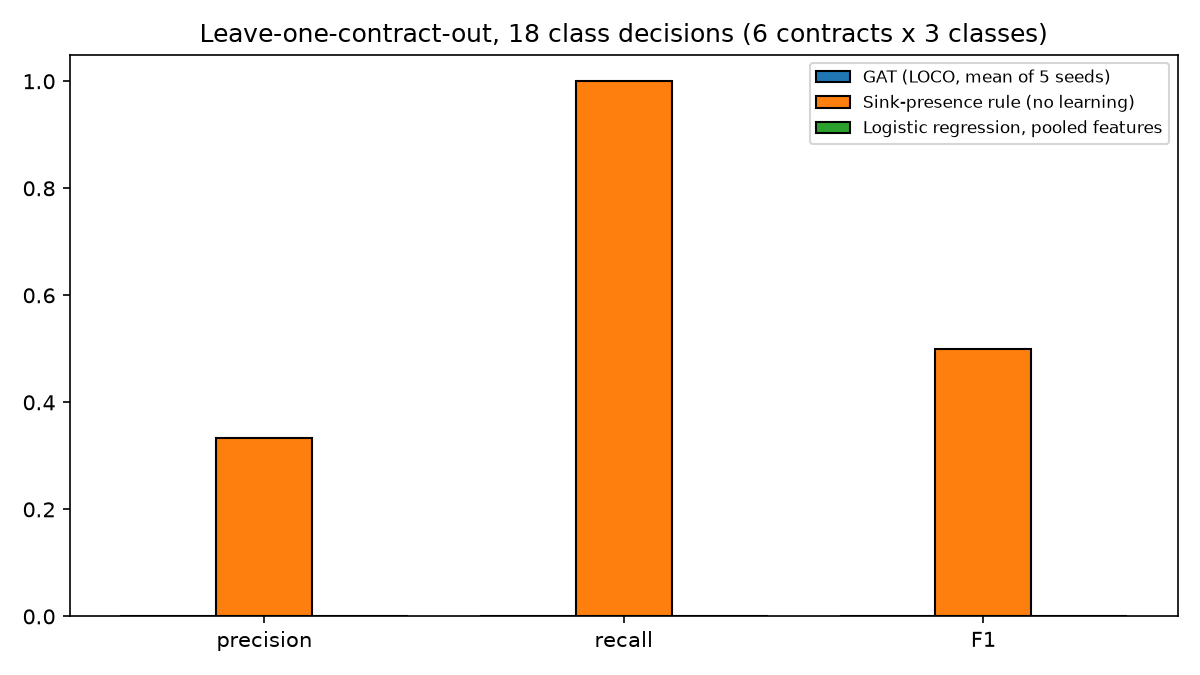

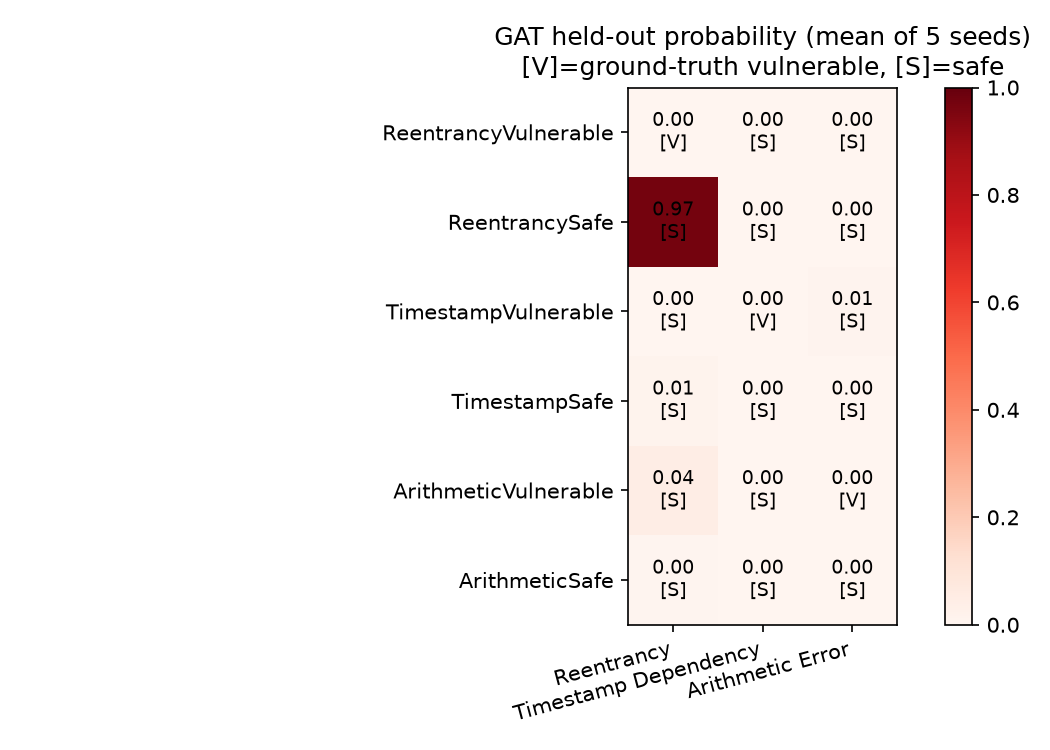

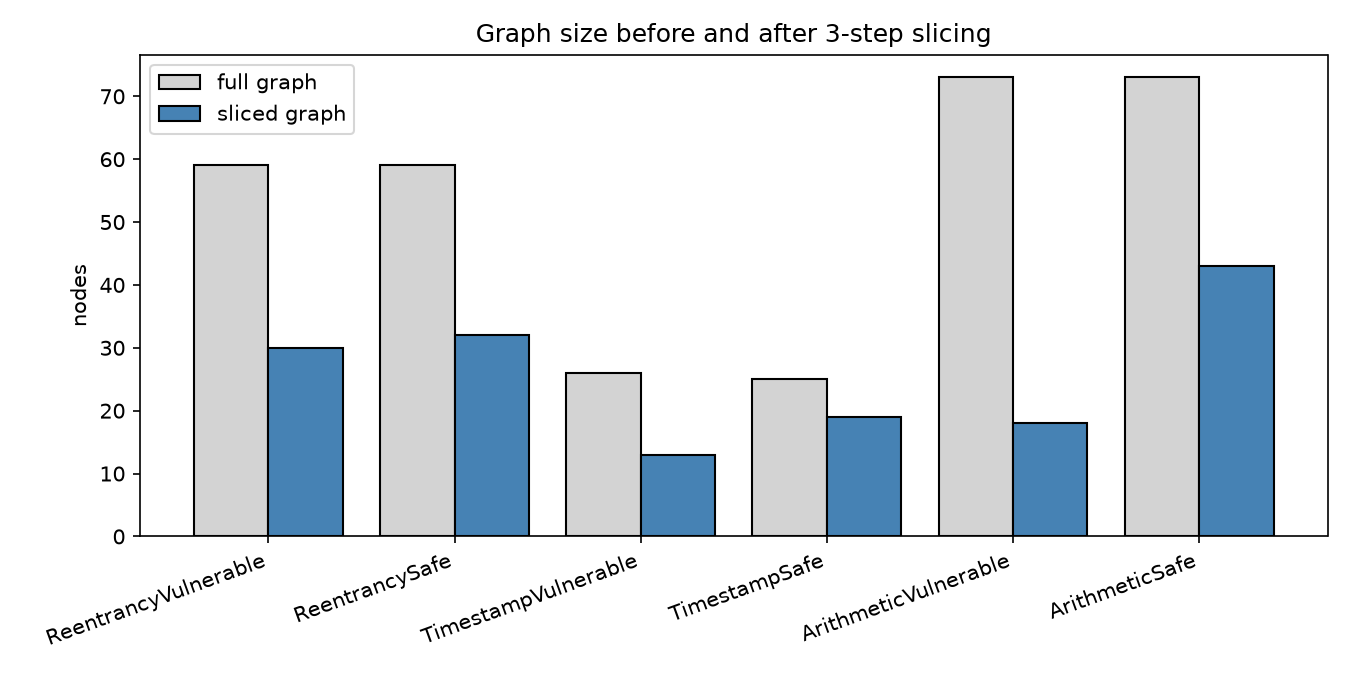

In [5]:
from IPython.display import Image, display
display(Image(filename="figures/fig_method_comparison.png", width=700))
display(Image(filename="figures/fig_loco_gat_heatmap.png", width=520))
display(Image(filename="figures/fig_slicing_sizes.png", width=700))

## 4. Reading the results

* The GAT never flags a held-out vulnerable contract. Its leave-one-out recall is 0, so the in-sample result does not carry over to unseen contracts.
* The sink-presence rule has the highest recall of the three methods. It also produces false positives on the safe contracts, because they contain the same sinks (external calls, arithmetic) as the vulnerable ones.
* Logistic regression predicts "safe" for every decision. Its accuracy comes from the class imbalance, not from detection.

Notebook 03 looks at individual decisions.